Dec06_21.44.55-4-s37.mrc: CTF fit resolution = 14.36 A


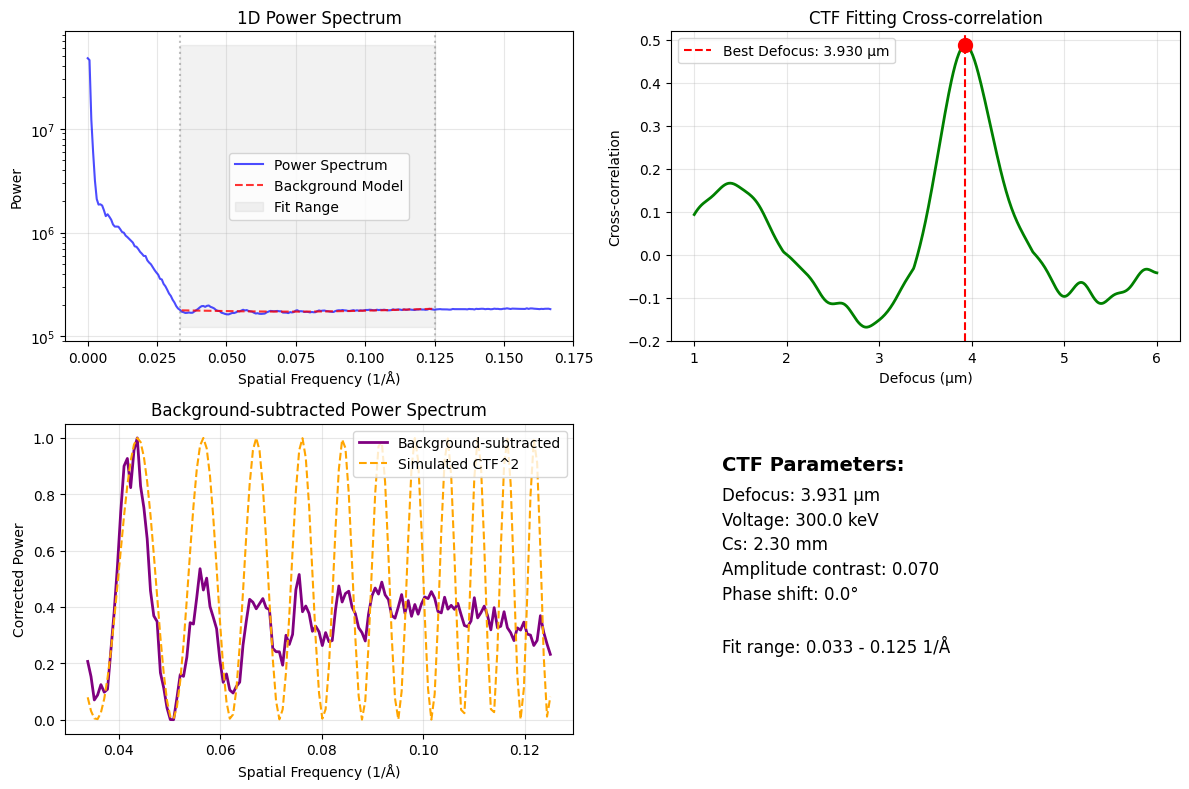

Dec06_21.44.55-4-s4.mrc: CTF fit resolution = 14.36 A


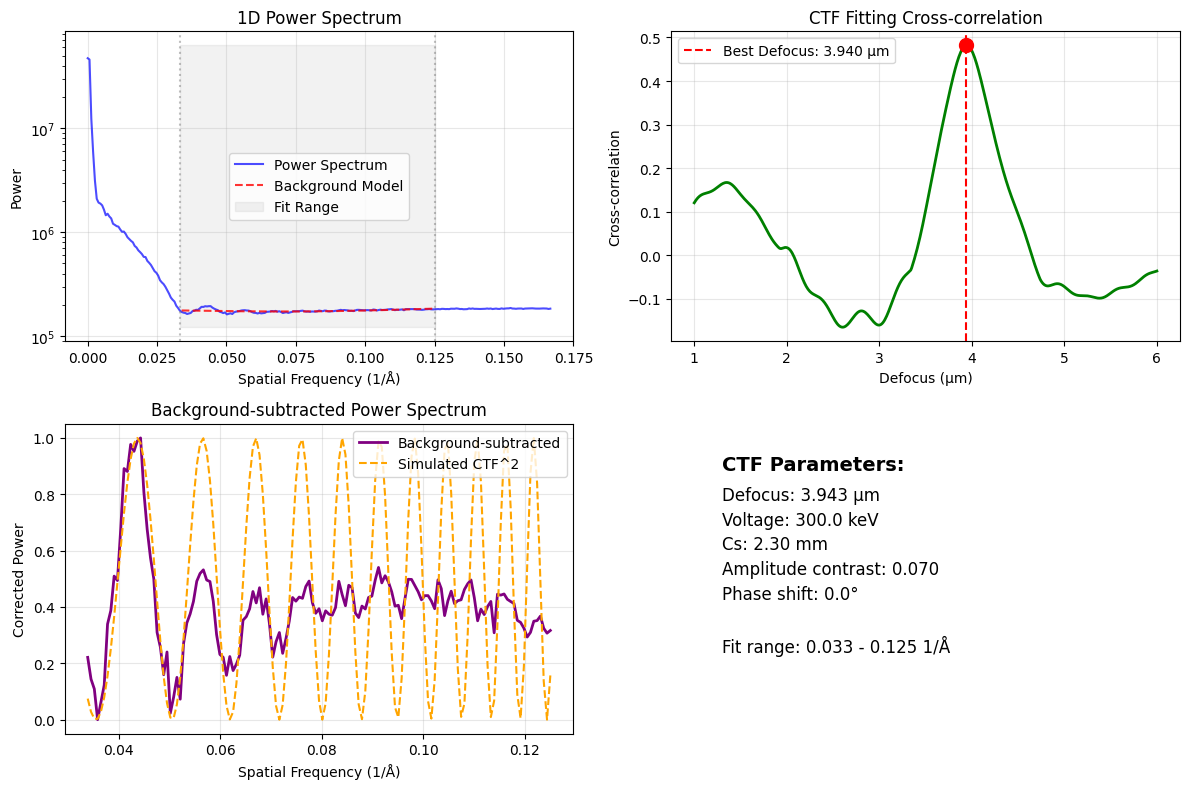

In [1]:
# https://github.com/fatiando/pooch
from pathlib import Path
import pooch
import torch
import mrcfile
import matplotlib.pyplot as plt

from torch_ctf_estimation import estimate_ctf
from torch_ctf_estimation.models import OpticalParams, CTFFittingParams
from torch_fourier_rescale import fourier_rescale_2d

from torch_ctf_estimation.utils.plotting import plot_1d_spectrum

GOODBOY = pooch.create(
    path=pooch.os_cache("torch-ctf-estimation"),
    base_url="https://zenodo.org/records/15871573/files/",
    registry={
        "Dec06_21.44.55-4-s37.mrc": "md5:a400900070223411b12e3db544789459",
        "Dec06_21.44.55-4-s4.mrc": "md5:46aa6b233f288d6af801b6216b3aa4c5"
    },
)

METADATA = {
    "Dec06_21.44.55-4-s37.mrc": {
        "pixel_spacing_angstroms": 2.571,
        "spherical_aberration_mm": 2.3,
        "voltage_kev": 300,
        "defocus_u": 4.0149,
        "defocus_v": 3.8507,
        "defocus_angle_deg": 83.09
    },
    "Dec06_21.44.55-4-s4.mrc": {
        "pixel_spacing_angstroms": 2.571,
        "spherical_aberration_mm": 2.3,
        "voltage_kev": 300,
        "defocus_u": 4.4071,
        "defocus_v": 3.9006,
        "defocus_angle_deg": 79.52,
    },
}



for key, value in GOODBOY.registry.items():
    image_file = GOODBOY.fetch(key, progressbar=True)
    image = mrcfile.read(image_file)
    image = torch.tensor(image).float()

    optical_params = OpticalParams(
        pixel_spacing_angstroms=METADATA[key]["pixel_spacing_angstroms"],
        voltage_kev=METADATA[key]["voltage_kev"],
        spherical_aberration_mm=METADATA[key]["spherical_aberration_mm"],
        amplitude_contrast_fraction=0.07,
    )
    fitting_params = CTFFittingParams(
        defocus_grid_resolution=(1, 2, 2),
        frequency_fit_range_angstroms=(30, 8),
        defocus_range_microns=(1, 6),
        patch_sidelength=512,
    )

    mean_ps, result1d, result2d = estimate_ctf(
        image=image,
        optical_params=optical_params,
        fitting_params=fitting_params,
    )

    # CTFFind-style max resolution of the CTF fit ("Thon rings with good fit up to")
    print(
        f"{key}: CTF fit resolution = "
        f"{result1d.ctf_fit_resolution_angstroms:.2f} A"
    )

    combined_powerspectrum = torch.hstack(
        [torch.flip(mean_ps[:,2:],dims=(1,0)), mean_ps]
    )
    plot_1d_spectrum(result1d)


In [ ]:
# === Compare against CTFFind on real data (CCMC / C3TFE) ===
# Reads CTFFind's RELION-style starfile (defocus + CtfMaxResolution) and runs our
# estimator on the same micrographs with the SAME parameters CTFFind used
# (pixel 0.8592 A, 200 kV, Cs 2.7, AC 0.1, fit range 30-5 A, box 512).
import os
import torch
import mrcfile

from torch_ctf_estimation import estimate_ctf
from torch_ctf_estimation.models import OpticalParams, CTFFittingParams

BASE = "/Users/tadej/Repositories/cryocloud/CCMC/data/C3TFE/CTFFind_data"
MICDIR = os.path.join(BASE, "jobs/CCMotionCorr/37/micrographs")
STAR = os.path.join(BASE, "p270_j40__micrographs_ctf.star")

# Parse the micrograph rows: name, defocusU, defocusV, ..., CtfMaxResolution (#9)
ref = {}
for line in open(STAR):
    if "_frames.mrc" in line and "loop_" not in line:
        p = line.split()
        ref[os.path.basename(p[0])] = {
            "defocus_A": 0.5 * (float(p[3]) + float(p[4])),
            "maxres_A": float(p[8]),
        }

optical = OpticalParams(
    pixel_spacing_angstroms=0.8592,
    voltage_kev=200,
    spherical_aberration_mm=2.7,
    amplitude_contrast_fraction=0.1,
)
fitting = CTFFittingParams(
    defocus_grid_resolution=(1, 2, 2),
    frequency_fit_range_angstroms=(30, 5),
    defocus_range_microns=(0.5, 5.0),
    patch_sidelength=512,
)

print(f"{'micrograph':10s} | {'CTFFind def/res':>18s} | {'ours def/res':>18s}")
print("-" * 56)
for name in sorted(ref):
    path = os.path.join(MICDIR, name)
    if not os.path.exists(path):
        continue
    image = torch.tensor(mrcfile.read(path)).float()
    mean_ps, result1d, result2d = estimate_ctf(
        image=image,
        optical_params=optical,
        fitting_params=fitting,
        device=torch.device("cpu"),
    )
    cf = ref[name]
    our_def = float(result1d.ctf_model.defocus_um) * 1e4
    tag = name.split("_")[-2]
    print(
        f"{tag:10s} | {cf['defocus_A']:8.0f} {cf['maxres_A']:6.2f} A "
        f"| {our_def:8.0f} {result1d.ctf_fit_resolution_angstroms:6.2f} A"
    )
